In [10]:
import os
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal


from Nonparametric.utils_model_design import generate_twub_design
from Nonparametric.utils_plot import plot_compare,plot_compare_bf_deteqv
from Nonparametric.nonparametric import deteqv_oracle_est,bona_fide_est

# Full-sib half-sib model
This notebook reproduces the simulation presented in Appendix E.

## Model Setup

Consider an experimental design in which each of the $I_1$ sires is mated with $M$ dams, so that the total number of dams is $I_2=I_1M$. The $m$-th dam mated with the $i$ th sire produces $J_{im}$ offspring, yielding a total sample size $n=\sum_{i=1}^{I_1}\sum_{m=1}^{M}J_{im}$. Let $J_i=\sum_{m=1}^{M}J_{im}$ denote the total number of offspring from sire $i$. For each offspring, we observe $p$ phenotypic traits. The observed trait matrix $Y\in\mathbb{R}^{n\times p}$ is assumed to follow the model
\begin{align*}
    Y=X\beta+U_1\alpha_1+U_2\alpha_2+U_3\alpha_3,
    \qquad
    \alpha_r\sim N(0,\text{Id}_{I_r}\otimes\Sigma_r).
\end{align*}
Here $X=\mathbb{1}_n$ is the fixed-effects design matrix, $\beta=\mu^T$ is the fixed effect,
$$
U_1=\text{diag}(\mathbb{1}_{J_1},\ldots,\mathbb{1}_{J_{I_1}})\in\mathbb{R}^{n\times I_1}
$$
assigns each offspring to its sire,
$$
U_2=\text{diag}(\mathbb{1}_{J_{11}},\ldots,\mathbb{1}_{J_{1M}},\ldots,\mathbb{1}_{J_{I_11}},\ldots,\mathbb{1}_{J_{I_1M}})\in\mathbb{R}^{n\times I_2}
$$
assigns each offspring to its dam, and $U_3=\text{Id}_n$ corresponds to the individual-level error. 

Consider the MANOVA estimator for $\Sigma_1$:
$$
S_n= \frac{1}{p}Y^TB_1Y,
$$
where the construction of $B_1$ is given in Appendix E.

Below, we compute the oracle, deterministic equivalent oracle, and bona fide nonparametric estimators for the spectrum of $\Sigma_1$ building on the MANOVA estimator $S_n$.

We set $\Sigma_2=\Sigma_3=I_p$, and study two scenarios for the spectrum of $\Sigma_1$:

- Linear decay. The eigenvalues satisfy $\tau_i=\tau_{\max} 1-(i-1)/p$, $i=1,\ldots,p$.
- Step decay. The eigenvalues satisfy $\tau_i=\tau_{\max}$ for $i=1,\ldots,p/2$, and $\tau_i=0$ for $i=p/2+1,\ldots,p$.


In [11]:
p = 50
I = 100
M = 2
I2 = I*M

U_list, B_list, J1, J2, n= generate_twub_design(I,M,p)
U1,U2,U3= U_list
B1_MANOVA,B2_MANOVA,B3_MANOVA = B_list
print("n: ",n)

Sigma2 = np.eye(p)
Sigma3 = np.eye(p)

cache = f'twub_p_{p}_I_{I}_M_{M}'
if not os.path.exists('image/'+cache+'/'):
    os.makedirs('image/'+cache+'/')
cache


n:  303


'twub_p_50_I_100_M_2'

In [12]:
def run_iteration(Sigma1, seed=1):
    np.random.seed(seed)

    alpha1 = multivariate_normal.rvs(mean=np.zeros(p), cov=Sigma1, size=I)
    alpha2 = multivariate_normal.rvs(mean=np.zeros(p), cov=Sigma2, size=len(J2))
    alpha3 = multivariate_normal.rvs(mean=np.zeros(p), cov=Sigma3, size=n)
    
    Y = np.ones((n,p)) + U_list[0]@alpha1 + U_list[1]@alpha2 + U_list[2]@alpha3
    Sn = 1/p*Y.T@B1_MANOVA@Y
    Lambda, U = np.linalg.eig(Sn.astype(np.float64))
    isort = np.argsort(Lambda)[::-1]
    Lambda = Lambda[isort]
    U = U[:, isort]    
    d_oracle = np.diag(U.T@Sigma1@U)  
    return Lambda,d_oracle,Y

## Oracle estimator

In [13]:
def plot_oracle(Sigma1_base,lam_max_list = [1,5,10],save=False):
    _,axes = plt.subplots(2,3,figsize=(8,5))

    for j in range(3):
        Sigma1 = Sigma1_base * lam_max_list[j]
        Lambda,d_oracle,_ = run_iteration(Sigma1)

        axes[0,j].plot(np.arange(p),np.diag(Sigma1),color='black',label='population')
        axes[0,j].plot(np.arange(p), d_oracle,color='blue', label='oracle')
        axes[0,j].set_title(r'$\tau_{\max}=$'+str(lam_max_list[j]))
        axes[1,j].plot(np.arange(p),np.diag(Sigma1),color='black',label='population')
        axes[1,j].plot(np.arange(p),Lambda,color='blue', label='MANOVA')
        axes[1,j].set_xlabel("Index")

    axes[0,0].set_ylabel("Eigenvalue")
    axes[0,0].legend()
    axes[1,0].set_ylabel("Eigenvalue")
    axes[1,0].legend()
    plt.tight_layout()
    if save:
        plt.savefig('image/'+save+'.pdf')
    plt.show()
    return


### linear decay

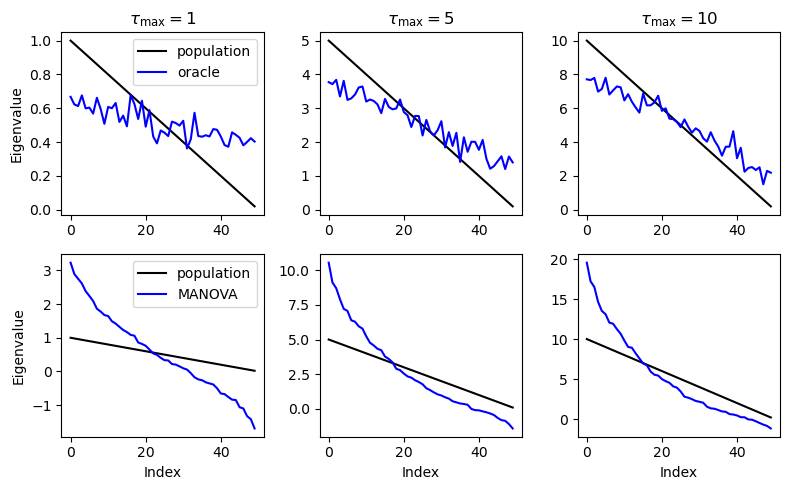

In [14]:
Sigma1_base = np.diag(np.arange(p, 0, -1) / p)
plot_oracle(Sigma1_base,save=cache+'/oracle_linear')

### step decay

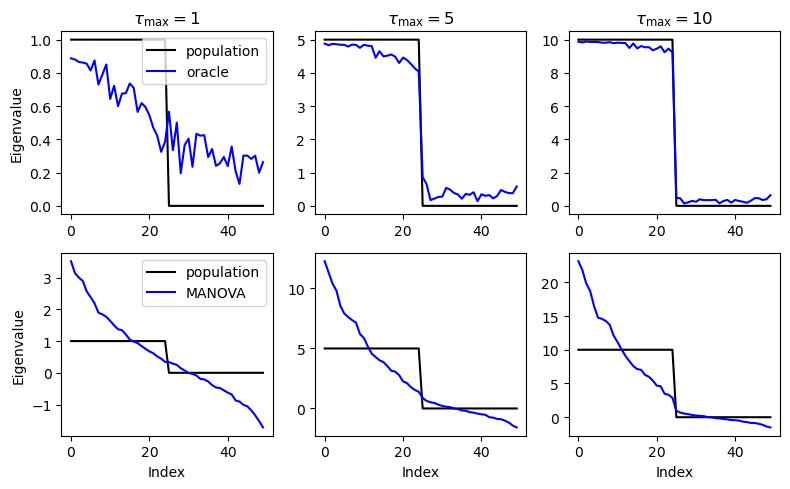

In [15]:
Sigma1_base = np.diag([1]*int(p/2)+[0]*int(p/2))
plot_oracle(Sigma1_base,save=cache+'/oracle_step')

## Deterministic equivalent oracle and bona fide nonparametric estimators
We consider the case $\tau_{\max}=5$.
### linear decay

In [16]:
Sigma1 = np.diag(np.arange(p, 0, -1) / p)*5
Lambda,d_oracle,Y = run_iteration(Sigma1)
Sigma_list = [Sigma1,Sigma2,Sigma3]
d_check,m_check_Im,a1_check_Im = deteqv_oracle_est(Y,Sigma_list,U_list,B1_MANOVA)
d_hat, d_iso, m_hat_Im, a1_hat_Im = bona_fide_est(Y, U_list, B1_MANOVA)

computing a_hat...: 100%|██████████| 50/50 [01:32<00:00,  1.86s/it]


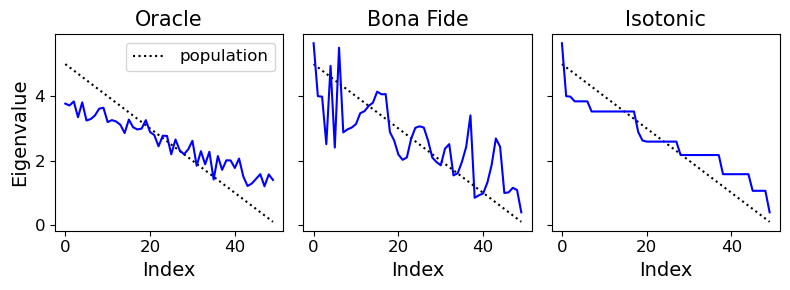

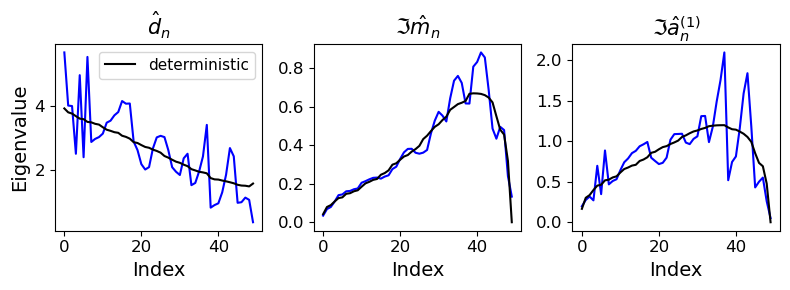

In [17]:
plot_compare(np.diag(Sigma1),d_oracle,d_hat,d_iso,save=cache+'/bf_linear')
plot_compare_bf_deteqv(d_hat,m_hat_Im,a1_hat_Im,d_check,m_check_Im,a1_check_Im,save=cache+'/deteqv_linear')

### step decay

In [18]:
Sigma1 = np.diag([1]*int(p/2)+[0]*int(p/2))*5
Lambda, d_oracle, Y = run_iteration(Sigma1)
Sigma_list = [Sigma1,Sigma2,Sigma3]
d_check, m_check_Im, a1_check_Im = deteqv_oracle_est(Y, Sigma_list, U_list, B1_MANOVA)
d_hat, d_iso, m_hat_Im, a1_hat_Im = bona_fide_est(Y, U_list, B1_MANOVA)

Calculating deterministic equivalent oracle...:   0%|          | 0/50 [00:00<?, ?it/s]

Calculating deterministic equivalent oracle...:   0%|          | 0/50 [00:36<?, ?it/s]


KeyboardInterrupt: 

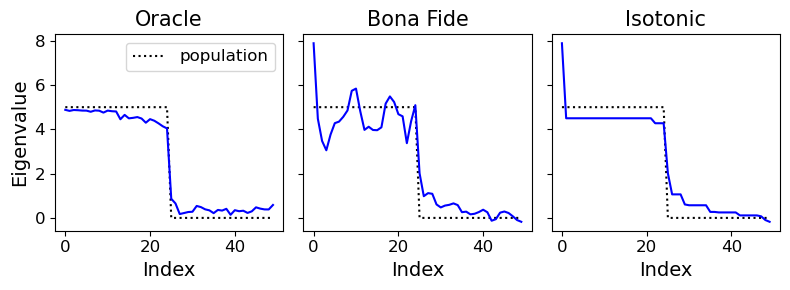

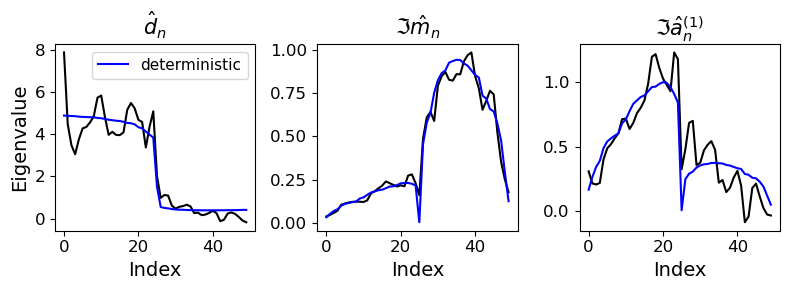

In [ ]:
plot_compare(np.diag(Sigma1),d_oracle,d_hat,d_iso,save=cache+'/bf_step')
plot_compare_bf_deteqv(d_hat,m_hat_Im,a1_hat_Im,d_check,m_check_Im,a1_check_Im,save=cache+'/deteqv_step')